# Waffle Chart

**Family:** Part-to-whole &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Part-to-whole:* Show how a single entity breaks down into its components.

## Design purpose

A 10 × 10 grid of squares, each worth 1% (or one unit). Squares are colored by category. Counting squares is more accurate than judging angles, and the 'n out of 100' framing is easy for any audience.

## When to use

- Communicate a few percentages to a general audience ('23 in every 100 customers')
- A pie-chart alternative that supports more accurate reading
- Show progress toward a goal

## Avoid when

- Values need precision finer than 1%
- There are more than ~5 categories

## Alternatives

- Pie chart
- Single 100% stacked bar
- Pictogram (isotype)

## Example

How a typical household's financial assets are split, per $100 (illustrative).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
s = pd.Series({"Cash & deposits": 40, "Stocks & funds": 45, "Bonds & other": 15})
assert s.sum() == 100
s

Cash & deposits    40
Stocks & funds     45
Bonds & other      15
dtype: int64

### Plot

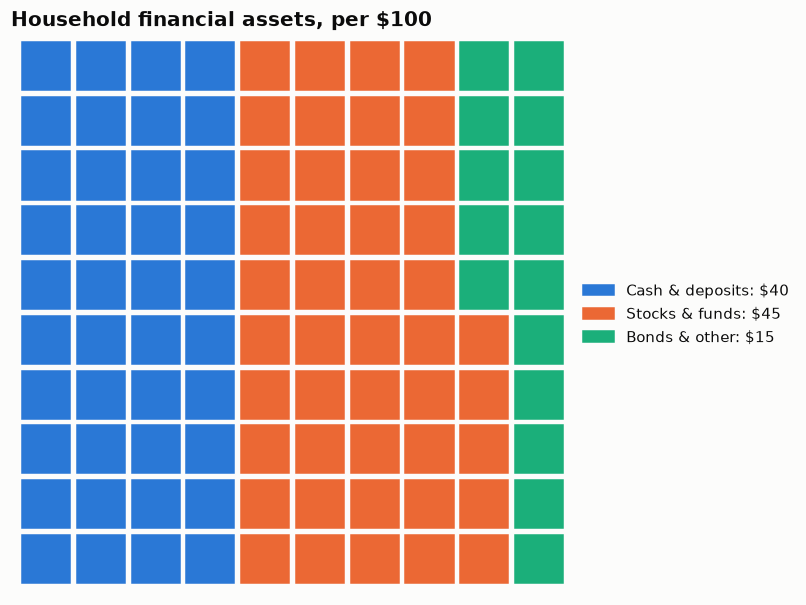

In [3]:
fig, ax = plt.subplots(figsize=(7, 5.6))
cells = np.repeat(np.arange(len(s)), s.values)
for k, cat in enumerate(cells):
    col, row = k // 10, k % 10          # fill column by column, bottom to top
    ax.add_patch(plt.Rectangle((col, row), 0.88, 0.88, color=PALETTE[cat]))
ax.set_xlim(-0.2, 10)
ax.set_ylim(-0.2, 10)
ax.set_aspect("equal")
ax.axis("off")
handles = [plt.Rectangle((0, 0), 1, 1, color=PALETTE[i]) for i in range(len(s))]
ax.legend(handles, [f"{k}: ${v}" for k, v in s.items()], loc="center left",
          bbox_to_anchor=(1.0, 0.5), fontsize=10)
ax.set_title("Household financial assets, per $100")
fig.tight_layout()
plt.show()

## How to read it

Each square is $1 of every $100 of financial assets. Fifteen squares, the green block, sit in bonds and other assets.

---
Standalone script: [`waffle_chart.py`](waffle_chart.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)